In [13]:
# ============================================================
# KHỞI TẠO: Import module & nạp dữ liệu lab
# ============================================================

import pandas as pd
import numpy as np

from data_quality import (
    audit,
    check_overview,
    check_plausibility,
    check_distribution,
    check_hidden_issues,
    check_logic,
)

# Đường dẫn (tính từ data/quality_checks/)
lab_input     = "../processed/lab_clean.csv"
patient_input = "../processed/patient_clean.csv"

df_lab = pd.read_csv(lab_input)
df_patient = pd.read_csv(patient_input)

print("Đã nạp lab_clean.csv    :", df_lab.shape)
print("Đã nạp patient_clean.csv:", df_patient.shape)
print("\n5 dòng đầu tiên của lab:")
display(df_lab.head())

Đã nạp lab_clean.csv    : (2265, 11)
Đã nạp patient_clean.csv: (2326, 5)

5 dòng đầu tiên của lab:


,patientunitstayid,creatinine_max,bun_mean,lactate_mean,lactate_max,wbc_mean,hemoglobin_mean,platelets_mean,bilirubin_mean,glucose_mean,glucose_max
0,141765,1.04,28.0,NaN,NaN,10.2,12.3,191.0,NaN,75.0,89.0
1,143870,1.14,13.5,NaN,NaN,11.7,12.3,152.0,NaN,131.5,140.0
2,144815,0.63,6.0,NaN,NaN,7.9,12.3,319.0,0.5,82.0,82.0
3,145427,1.05,14.0,NaN,NaN,21.1,13.3,196.0,NaN,128.5,139.0
4,147306,0.65,NaN,NaN,NaN,13.5,12.1,280.0,NaN,NaN,NaN


In [14]:
# ============================================================
# KIỂM TRA CHUNG: dùng module data_quality
# ============================================================
# lab_clean.csv không có cột nhãn mortality (đã tách riêng),
# nên truyền label_col=None.
#
# Ngưỡng plausibility cho 10 đặc trưng xét nghiệm:
#   - creatinine_max: 0.1–20 mg/dL
#   - bun_mean: 1–200 mg/dL
#   - lactate_mean/max: 0.1–30 mmol/L
#   - wbc_mean: 0.1–100 K/µL
#   - hemoglobin_mean: 2–25 g/dL
#   - platelets_mean: 1–1000 K/µL
#   - bilirubin_mean: 0.1–50 mg/dL
#   - glucose_mean/max: 10–1000 mg/dL

LAB_RULES = {
    "creatinine_max":   (0.1, 20,   "mg/dL"),
    "bun_mean":         (1,   200,  "mg/dL"),
    "lactate_mean":     (0.1, 30,   "mmol/L"),
    "lactate_max":      (0.1, 30,   "mmol/L"),
    "wbc_mean":         (0.1, 100,  "K/µL"),
    "hemoglobin_mean":  (2,   25,   "g/dL"),
    "platelets_mean":   (1,   1000, "K/µL"),
    "bilirubin_mean":   (0.1, 50,   "mg/dL"),
    "glucose_mean":     (10,  1000, "mg/dL"),
    "glucose_max":      (10,  1000, "mg/dL"),
}

audit(
    df_lab,
    name="lab_clean.csv",
    label_col=None,
    plausibility_rules=LAB_RULES,
)


TỔNG QUAN: lab_clean.csv
Kích thước : 2,265 dòng × 11 cột
Bộ nhớ     : 194.8 KB

Kiểu dữ liệu:
patientunitstayid      int64
creatinine_max       float64
bun_mean             float64
lactate_mean         float64
lactate_max          float64
wbc_mean             float64
hemoglobin_mean      float64
platelets_mean       float64
bilirubin_mean       float64
glucose_mean         float64
glucose_max          float64

Missing values:
                 missing    pct
creatinine_max       173   7.64
bun_mean             176   7.77
lactate_mean        1796  79.29
lactate_max         1796  79.29
wbc_mean             310  13.69
hemoglobin_mean      295  13.02
platelets_mean       345  15.23
bilirubin_mean      1327  58.59
glucose_mean          73   3.22
glucose_max           73   3.22

Số dòng trùng lặp hoàn toàn: 0

KIỂM TRA PLAUSIBILITY (ngưỡng sinh lý)
⚠️ creatinine_max  | min=      0.10 max=     20.20 | ngoài [0.1, 20] (mg/dL): 1 dòng
✅ bun_mean        | min=      2.00 max=    197.60 | ngoài [

In [15]:
# ============================================================
# KIỂM TRA RIÊNG: Khóa chính
# ============================================================

print("=" * 60)
print("KIỂM TRA RIÊNG: KHÓA CHÍNH")
print("=" * 60)

n_rows   = len(df_lab)
n_unique = df_lab["patientunitstayid"].nunique()
n_dup    = n_rows - n_unique

print(f"\nSố dòng              : {n_rows:,}")
print(f"Số patientunitstayid : {n_unique:,}")
print(f"Số trùng lặp         : {n_dup}")
print(f"{'✅' if n_dup == 0 else '⚠️'} Khóa chính duy nhất")

n_bad_id = (df_lab["patientunitstayid"] <= 0).sum()
print(f"{'✅' if n_bad_id == 0 else '⚠️'} patientunitstayid <= 0: {n_bad_id} dòng")

KIỂM TRA RIÊNG: KHÓA CHÍNH

Số dòng              : 2,265
Số patientunitstayid : 2,265
Số trùng lặp         : 0
✅ Khóa chính duy nhất
✅ patientunitstayid <= 0: 0 dòng


In [16]:
# ============================================================
# KIỂM TRA RIÊNG: Tỷ lệ NaN của 10 đặc trưng xét nghiệm
# ============================================================
# Đánh giá mức độ thiếu:
#   - < 10%  : tốt
#   - 10-50% : chấp nhận
#   - > 50%  : rất thưa, cân nhắc bỏ cột

print("=" * 60)
print("KIỂM TRA RIÊNG: TỶ LỆ NaN CỦA 10 ĐẶC TRƯNG")
print("=" * 60)

feature_cols = [c for c in df_lab.columns if c != "patientunitstayid"]

print(f"\n{'Đặc trưng':20s} {'NaN':>6s} {'Tỷ lệ':>8s}  Đánh giá")
print("-" * 60)
for col in feature_cols:
    n_miss = df_lab[col].isna().sum()
    pct = n_miss / len(df_lab) * 100
    if pct < 10:
        status = "✅ Tốt"
    elif pct < 50:
        status = "ℹ️ Chấp nhận"
    else:
        status = "⚠️ Rất thưa"
    print(f"{col:20s} {n_miss:>6,} {pct:>7.2f}%  {status}")

KIỂM TRA RIÊNG: TỶ LỆ NaN CỦA 10 ĐẶC TRƯNG

Đặc trưng               NaN    Tỷ lệ  Đánh giá
------------------------------------------------------------
creatinine_max          173    7.64%  ✅ Tốt
bun_mean                176    7.77%  ✅ Tốt
lactate_mean          1,796   79.29%  ⚠️ Rất thưa
lactate_max           1,796   79.29%  ⚠️ Rất thưa
wbc_mean                310   13.69%  ℹ️ Chấp nhận
hemoglobin_mean         295   13.02%  ℹ️ Chấp nhận
platelets_mean          345   15.23%  ℹ️ Chấp nhận
bilirubin_mean        1,327   58.59%  ⚠️ Rất thưa
glucose_mean             73    3.22%  ✅ Tốt
glucose_max              73    3.22%  ✅ Tốt


In [17]:
# ============================================================
# KIỂM TRA RIÊNG: Phân bố & outlier từng đặc trưng
# ============================================================

print("=" * 60)
print("KIỂM TRA RIÊNG: PHÂN BỐ & OUTLIER")
print("=" * 60)

for col in feature_cols:
    s = df_lab[col].dropna()
    if len(s) == 0:
        print(f"\n{col}: toàn bộ NaN")
        continue
    print(f"\n--- {col} ---")
    print(f"  count={len(s):,}  mean={s.mean():.2f}  std={s.std():.2f}")
    print(f"  min={s.min():.2f}  q25={s.quantile(.25):.2f}  "
          f"median={s.median():.2f}  q75={s.quantile(.75):.2f}  max={s.max():.2f}")
    # Outlier theo IQR
    q1, q3 = s.quantile(.25), s.quantile(.75)
    iqr = q3 - q1
    n_outlier = ((s < q1 - 3 * iqr) | (s > q3 + 3 * iqr)).sum()
    if n_outlier > 0:
        print(f"  ℹ️ Outlier (ngoài 3×IQR): {n_outlier} dòng "
              f"({n_outlier/len(s)*100:.2f}%)")

KIỂM TRA RIÊNG: PHÂN BỐ & OUTLIER

--- creatinine_max ---
  count=2,092  mean=1.50  std=1.58
  min=0.10  q25=0.77  median=1.00  q75=1.56  max=20.20
  ℹ️ Outlier (ngoài 3×IQR): 111 dòng (5.31%)

--- bun_mean ---
  count=2,089  mean=24.83  std=18.61
  min=2.00  q25=13.00  median=19.00  q75=31.00  max=197.60
  ℹ️ Outlier (ngoài 3×IQR): 24 dòng (1.15%)

--- lactate_mean ---
  count=469  mean=2.48  std=2.76
  min=0.30  q25=1.20  median=1.70  q75=2.53  max=27.90
  ℹ️ Outlier (ngoài 3×IQR): 27 dòng (5.76%)

--- lactate_max ---
  count=469  mean=2.80  std=3.14
  min=0.30  q25=1.20  median=1.80  q75=3.10  max=27.90
  ℹ️ Outlier (ngoài 3×IQR): 20 dòng (4.26%)

--- wbc_mean ---
  count=1,955  mean=11.40  std=6.71
  min=0.10  q25=7.20  median=10.00  q75=14.00  max=82.50
  ℹ️ Outlier (ngoài 3×IQR): 24 dòng (1.23%)

--- hemoglobin_mean ---
  count=1,970  mean=11.15  std=2.22
  min=4.40  q25=9.40  median=11.20  q75=12.80  max=18.60

--- platelets_mean ---
  count=1,920  mean=203.42  std=93.30
  min=1

In [18]:
# ============================================================
# KIỂM TRA RIÊNG: So sánh cohort — ai thiếu lab?
# ============================================================
# Merge patient_clean với lab_clean để xem:
#   - Bao nhiêu bệnh nhân trong cohort KHÔNG có lab
#   - Nhóm thiếu lab có tử vong khác biệt không

print("=" * 60)
print("KIỂM TRA RIÊNG: SO SÁNH COHORT")
print("=" * 60)

df_check = df_patient.merge(df_lab, on="patientunitstayid", how="left")

# Kiểm tra có ít nhất 1 xét nghiệm không
df_check["lab_missing"] = df_check["creatinine_max"].isna() & \
                          df_check["bun_mean"].isna() & \
                          df_check["lactate_mean"].isna()

print(f"\nSố bệnh nhân trong cohort     : {len(df_patient):,}")
print(f"Số bệnh nhân có ít nhất 1 lab : {(~df_check['lab_missing']).sum():,}")
print(f"Số bệnh nhân THIẾU hoàn toàn  : {df_check['lab_missing'].sum():,}")

# So sánh tỷ lệ tử vong: có lab vs thiếu lab
print("\nSo sánh tỷ lệ tử vong: có lab vs thiếu lab")
result = df_check.groupby("lab_missing")["mortality"].agg(
    count="count", deaths="sum", mortality_rate="mean"
).round(4)
result.index = ["Có lab", "Thiếu lab"]
print(result.to_string())

# So sánh nhóm thiếu từng xét nghiệm quan trọng
for col in ["lactate_mean", "creatinine_max", "bun_mean"]:
    print(f"\nSo sánh tỷ lệ tử vong: có vs thiếu {col}")
    df_check[f"{col}_missing"] = df_check[col].isna()
    result = df_check.groupby(f"{col}_missing")["mortality"].agg(
        count="count", deaths="sum", mortality_rate="mean"
    ).round(4)
    result.index = [f"Có {col}", f"Thiếu {col}"]
    print(result.to_string())

KIỂM TRA RIÊNG: SO SÁNH COHORT

Số bệnh nhân trong cohort     : 2,326
Số bệnh nhân có ít nhất 1 lab : 2,029
Số bệnh nhân THIẾU hoàn toàn  : 297

So sánh tỷ lệ tử vong: có lab vs thiếu lab
           count  deaths  mortality_rate
Có lab      2029     165          0.0813
Thiếu lab    297      26          0.0875

So sánh tỷ lệ tử vong: có vs thiếu lactate_mean
                    count  deaths  mortality_rate
Có lactate_mean       456      78          0.1711
Thiếu lactate_mean   1870     113          0.0604

So sánh tỷ lệ tử vong: có vs thiếu creatinine_max
                      count  deaths  mortality_rate
Có creatinine_max      2010     161          0.0801
Thiếu creatinine_max    316      30          0.0949

So sánh tỷ lệ tử vong: có vs thiếu bun_mean
                count  deaths  mortality_rate
Có bun_mean      2007     160          0.0797
Thiếu bun_mean    319      31          0.0972


In [19]:
# ============================================================
# KIỂM TRA RIÊNG: Tương quan giữa 10 đặc trưng
# ============================================================
# Tương quan cao (> 0.9) giữa 2 đặc trưng → dư thừa.
# Ví dụ: lactate_mean và lactate_max có thể tương quan mạnh.

print("=" * 60)
print("KIỂM TRA RIÊNG: TƯƠNG QUAN")
print("=" * 60)

corr = df_lab[feature_cols].corr().round(2)

print("\nCác cặp tương quan |r| > 0.5:")
print("-" * 60)

found = False
for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        c1, c2 = feature_cols[i], feature_cols[j]
        r = corr.loc[c1, c2]
        if abs(r) > 0.5:
            print(f"  {c1:20s} ↔ {c2:20s}: r = {r:+.2f}")
            found = True
if not found:
    print("  ✅ Không có cặp tương quan cao (|r| > 0.5)")

KIỂM TRA RIÊNG: TƯƠNG QUAN

Các cặp tương quan |r| > 0.5:
------------------------------------------------------------
  creatinine_max       ↔ bun_mean            : r = +0.61
  lactate_mean         ↔ lactate_max         : r = +0.97
  glucose_mean         ↔ glucose_max         : r = +0.86


In [20]:
# ============================================================
# KẾT LUẬN: Checklist chất lượng lab_clean.csv
# ============================================================

print("=" * 60)
print("CHECKLIST CHẤT LƯỢNG: lab_clean.csv")
print("=" * 60)

def check_range(series, lo, hi):
    s = series.dropna()
    return ((s >= lo) & (s <= hi)).all() if len(s) > 0 else True

checks = {
    "Khóa chính duy nhất":           df_lab["patientunitstayid"].duplicated().sum() == 0,
    "Không có dòng trùng hoàn toàn": df_lab.duplicated().sum() == 0,
    "patientunitstayid > 0":         (df_lab["patientunitstayid"] > 0).all(),
    "creatinine trong [0.1, 20]":    check_range(df_lab["creatinine_max"], 0.1, 20),
    "lactate trong [0.1, 30]":       check_range(df_lab["lactate_mean"], 0.1, 30),
    "wbc trong [0.1, 100]":          check_range(df_lab["wbc_mean"], 0.1, 100),
    "hemoglobin trong [2, 25]":      check_range(df_lab["hemoglobin_mean"], 2, 25),
    "glucose trong [10, 1000]":      check_range(df_lab["glucose_mean"], 10, 1000),
    "Tỷ lệ NaN lactate < 50%":       df_lab["lactate_mean"].isna().mean() < 0.50,
    "Tỷ lệ NaN creatinine < 30%":    df_lab["creatinine_max"].isna().mean() < 0.30,
}

for name, passed in checks.items():
    print(f"{'✅' if passed else '❌'} {name}")

n_pass  = sum(checks.values())
n_total = len(checks)
print(f"\nKết quả: {n_pass}/{n_total} kiểm tra đạt")

if n_pass == n_total:
    print("\n🎉 DỮ LIỆU LAB SẴN SÀNG cho bước merge!")
else:
    print(f"\n⚠️ Còn {n_total - n_pass} vấn đề cần xem xét.")

CHECKLIST CHẤT LƯỢNG: lab_clean.csv
✅ Khóa chính duy nhất
✅ Không có dòng trùng hoàn toàn
✅ patientunitstayid > 0
❌ creatinine trong [0.1, 20]
✅ lactate trong [0.1, 30]
✅ wbc trong [0.1, 100]
✅ hemoglobin trong [2, 25]
✅ glucose trong [10, 1000]
❌ Tỷ lệ NaN lactate < 50%
✅ Tỷ lệ NaN creatinine < 30%

Kết quả: 8/10 kiểm tra đạt

⚠️ Còn 2 vấn đề cần xem xét.


In [21]:
s = df_lab["wbc_mean"].dropna()
print("wbc ngoài [0.1, 100]:")
print(s[(s < 0.1) | (s > 100)].describe())
print(f"Số dòng: {((s < 0.1) | (s > 100)).sum()}")

wbc ngoài [0.1, 100]:
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: wbc_mean, dtype: float64
Số dòng: 0


Thống kê wbc_mean:
count    1955.000000
mean       11.396996
std         6.707958
min         0.100000
25%         7.200000
50%        10.000000
75%        14.000000
max        82.500000
Name: wbc_mean, dtype: float64

Số dòng WBC > 100: 0
Series([], )

Phân bố WBC theo khoảng:
wbc_mean
<4 (thấp)               86
4-11 (bình thường)    1049
11-20 (cao nhẹ)        662
20-50 (cao)            155
50-100 (rất cao)         3
>100 (cực cao/lỗi)       0


/tmp/ipykernel_37458/1714636736.py:32: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df_lab["wbc_mean"].dropna(), vert=False)


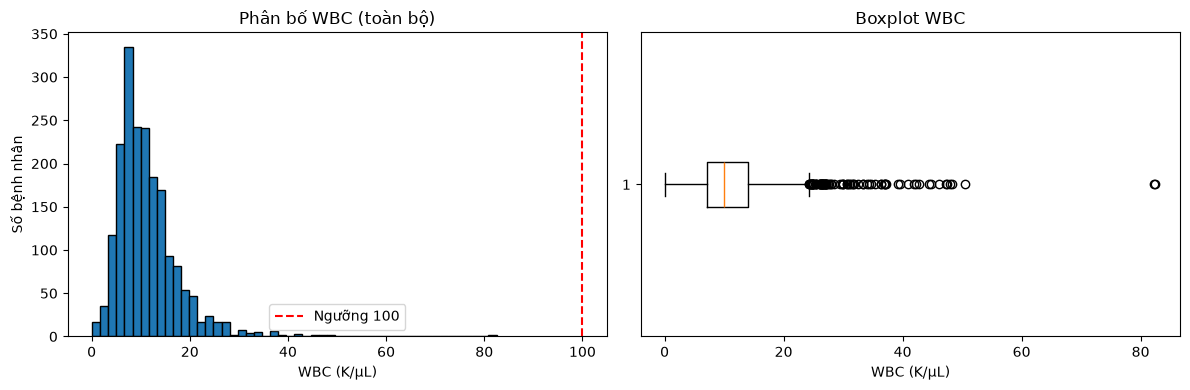

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Thống kê tổng quan
print("Thống kê wbc_mean:")
print(df_lab["wbc_mean"].describe())

# 2. Các dòng WBC > 100
wbc_high = df_lab[df_lab["wbc_mean"] > 100]["wbc_mean"]
print(f"\nSố dòng WBC > 100: {len(wbc_high)}")
print(wbc_high.to_string())

# 3. Phân bố theo khoảng
bins = [0, 4, 11, 20, 50, 100, 500]
labels = ["<4 (thấp)", "4-11 (bình thường)", "11-20 (cao nhẹ)",
          "20-50 (cao)", "50-100 (rất cao)", ">100 (cực cao/lỗi)"]
print("\nPhân bố WBC theo khoảng:")
print(pd.cut(df_lab["wbc_mean"], bins=bins, labels=labels)
      .value_counts().sort_index().to_string())

# 4. Vẽ histogram + boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_lab["wbc_mean"].dropna(), bins=50, edgecolor="black")
axes[0].set_title("Phân bố WBC (toàn bộ)")
axes[0].set_xlabel("WBC (K/µL)")
axes[0].set_ylabel("Số bệnh nhân")
axes[0].axvline(100, color="red", linestyle="--", label="Ngưỡng 100")
axes[0].legend()

axes[1].boxplot(df_lab["wbc_mean"].dropna(), vert=False)
axes[1].set_title("Boxplot WBC")
axes[1].set_xlabel("WBC (K/µL)")

plt.tight_layout()
plt.show()